In [41]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
import warnings
warnings.filterwarnings('ignore')

from pdm_model import Net, SimpleNet

# Set device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

Using device: cuda


In [42]:
def norm(x,y):
    return np.sqrt(x**2 + y**2)
def rosenbrock(x,y):
    return (1 - x)**2 + 100 * (y - x**2)**2
def f3(x,y):
    return x**2 + np.sin(np.pi * y)

In [43]:
class SymbolDataset(Dataset):
    """
    Dataset for the adding problem task.

    Args:
        seq_len: Length of the sequence (default: 20)
        num_samples: Number of samples in the dataset
    """

    def __init__(self, seq_len=20, num_samples=1000):

        np.random.seed(42)  # For reproducibility

        self.seq_len = seq_len
        self.num_samples = num_samples
        self.data = np.random.uniform(0, 1, size=(num_samples, seq_len))
        target = f3(self.data[:,0], self.data[:,1])
        self.data = torch.FloatTensor(self.data).unsqueeze(-1)
        self.targets = torch.FloatTensor(target)
        # print('results:', self.targets[:20])
        self.input_size = self.data.shape[-1]
        self.output_size = 1

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        return self.data[idx], self.targets[idx]

# Create datasets
train_dataset = SymbolDataset(seq_len=2, num_samples=50000)
test_dataset = SymbolDataset(seq_len=2, num_samples=2000)

print(f"Training dataset size: {len(train_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")

# Show example


for i in range(10):
    print(f"Input: {train_dataset[i][0].squeeze().numpy()}, Target: {train_dataset[i][1].item()}")

batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

Training dataset size: 50000
Test dataset size: 2000
Input: [0.37454012 0.9507143 ], Target: 0.29449793696403503
Input: [0.7319939 0.5986585], Target: 1.4881654977798462
Input: [0.15601864 0.15599452], Target: 0.49503055214881897
Input: [0.05808361 0.8661761 ], Target: 0.4115176498889923
Input: [0.601115  0.7080726], Target: 1.1551910638809204
Input: [0.02058449 0.96990985], Target: 0.09481398016214371
Input: [0.83244264 0.21233912], Target: 1.3116576671600342
Input: [0.18182497 0.1834045 ], Target: 0.5778868794441223
Input: [0.30424225 0.52475643], Target: 1.0895403623580933
Input: [0.43194503 0.29122913], Target: 0.9790922999382019


In [44]:
def train_model(model, train_dataset, test_dataset, epochs=100, lr=0.001, batch_size=64):
    """
    Train a model on the adding problem.
    """
    if isinstance(model, Net):
        special_params, other_params = [], []
        for name, p in model.named_parameters():
            if name == "lstm.eimask_logit":   # 或者用 name.endswith("eimask_logit")
                special_params.append(p)
                # assert p.requires_grad, "eimask_logit should be trainable"
            else:
                other_params.append(p)
        optimizer = torch.optim.Adam([{'params': special_params, 'lr': lr},
                                      {'params': other_params, 'lr': lr}])
    else:
        # For SimpleNet, use a single learning rate
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()  # Use CrossEntropyLoss for classification

    train_losses = torch.zeros(epochs)
    test_every = 100
    test_losses = torch.zeros(epochs // test_every)

    model.train()
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    loader = iter(train_loader)
    for epoch in range(epochs):
        # print(epoch)
        # Training
        # if isinstance(model, Net):
        #     model.temperature = get_temperature(epoch, epochs)
            # if epoch % 100 == 0:
            #     print(f"Epoch {epoch}: Temperature = {model.temperature:.4f}")
            #     eimask = model.lstm.eimask_logit.detach().cpu().numpy()
            #     fig, ax = plt.subplots(1,1,figsize=(8, 2))
            #     ax.plot(eimask[:, 0], label='Excitatory', color='C1')
            #     ax.plot(eimask[:, 1], label='Inhibitory', color='C0')
            #     ax.set_title('EI mask')
            #     ax.set_xlabel('Neuron index')
            #     ax.set_ylabel('Logit value')
            #     ax.legend()
            #     plt.show()
            #     plt.close()
        total_train_loss = 0
        num_batches = 0

        # for batch_inputs, batch_targets in train_loader:
        try:
            batch_inputs, batch_targets = next(loader)
        except StopIteration:
            train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
            loader = iter(train_loader)
            batch_inputs, batch_targets = next(loader)
        batch_inputs = batch_inputs.to(device).transpose(0, 1)  # (seq_len, batch_size, input_size)
        # print('batch_targets:', batch_targets.shape)
        batch_targets = batch_targets.to(device)

        optimizer.zero_grad()

        # Forward pass
        outputs, eimask_logit, hidden = model(batch_inputs)

        # Use the last output for regression
        predictions = outputs[-1, :]  # Last time step, all batches

        decoding_loss = criterion(predictions, batch_targets)

        if model.entropy_loss:
            eimask_prob = F.softmax(eimask_logit, dim=-1)
            eimask_entropy = -torch.sum(eimask_prob * torch.log(eimask_prob + 1e-10), dim=-1)
            entropy_loss = torch.mean(eimask_entropy)  # Add entropy regularization
        else:
            entropy_loss = 0.0

        loss = 1 * entropy_loss + decoding_loss
        # Backward pass
        loss.backward()
        # Gradient clipping for stability
        # torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()

        total_train_loss += loss.item()
        num_batches += 1

        avg_train_loss = total_train_loss / num_batches
        train_losses[epoch] = avg_train_loss

        # Testing
        if epoch % test_every == 0:
            model.eval()
            total_test_loss = 0
            num_test_batches = 0

            with torch.no_grad():
                for batch_inputs, batch_targets in test_loader:
                    batch_inputs = batch_inputs.to(device).transpose(0, 1)
                    batch_targets = batch_targets.to(device)

                    outputs, _, hidden = model(batch_inputs)
                    predictions = outputs[-1, :]

                    loss = criterion(predictions, batch_targets)
                    total_test_loss += loss.item()
                    num_test_batches += 1

            avg_test_loss = total_test_loss / num_test_batches
            test_losses[epoch // test_every] = avg_test_loss

            print(f'Epoch [{epoch:4d}/{epochs}], Train Loss: {avg_train_loss:.6f}, Test Loss: {avg_test_loss:.6f}')

            model.train()

    return train_losses, test_losses

def evaluate_model(model, test_loader):
    """
    Evaluate model performance on test set.
    """
    model.eval()
    total_loss = 0
    predictions = []
    targets = []

    criterion = nn.MSELoss()

    with torch.no_grad():
        for batch_inputs, batch_targets in test_loader:
            batch_inputs = batch_inputs.to(device).transpose(0, 1)
            batch_targets = batch_targets.to(device)

            outputs, _, hidden = model(batch_inputs)
            preds = outputs[-1, :]

            loss = criterion(preds, batch_targets)
            total_loss += loss.item()

            predictions.extend(preds.cpu().numpy())
            targets.extend(batch_targets.cpu().numpy())

    avg_loss = total_loss / len(test_loader)

    return avg_loss, predictions, targets

In [45]:
# Experiment parameters
n_seeds = 5
epochs = 3000

hidden_size = 64
input_size = train_dataset.input_size  # [number, indicator]
output_size = train_dataset.output_size  # regression output

# Create data loaders


# Storage for results
results = {
    'net': {'train_losses': [], 'test_losses': [], 'final_loss':[]},
    'simple': {'train_losses': [], 'test_losses': [], 'final_loss':[]}
}
ei_logit_arr = np.zeros((n_seeds, hidden_size, 2))
print(f"Running experiment with {n_seeds} seeds...\n")
lr_ei = 1e-2
lr_simple = 1e-2
for seed in range(n_seeds):
    print(f"=== Seed {seed + 1}/{n_seeds} ===")

    # Set random seeds for reproducibility
    torch.manual_seed(seed)
    np.random.seed(seed)

    # Train Net (EI-separated RNN)
    print("Training Net (EI-separated RNN)...")
    net = Net(ob_size=input_size, num_h=hidden_size, act_size=output_size, entropy_loss=True).to(device)

    train_losses_net, test_losses_net = train_model(net, train_dataset, test_dataset,
                                                  epochs=epochs, lr=lr_ei, batch_size=batch_size,)

    # Evaluate Net
    loss_net, net_predictions, net_targets = evaluate_model(net, test_loader)

    results['net']['train_losses'].append(train_losses_net.detach().cpu().numpy())
    results['net']['test_losses'].append(test_losses_net.detach().cpu().numpy())
    results['net']['final_loss'].append(loss_net)
    print(f"Net - Final Loss: {loss_net:.6f}")

    # Train SimpleNet (vanilla RNN)
    print("Training SimpleNet (vanilla RNN)...")
    simple_net = SimpleNet(ob_size=input_size, num_h=hidden_size, act_size=output_size).to(device)
    train_losses_simple, test_losses_simple = train_model(simple_net, train_dataset, test_dataset,
                                                          epochs=epochs,lr=lr_simple,batch_size=batch_size,)

    # Evaluate SimpleNet
    loss_simple, simple_predictions, simple_targets = evaluate_model(simple_net, test_loader)

    results['simple']['train_losses'].append(train_losses_simple.detach().cpu().numpy())
    results['simple']['test_losses'].append(test_losses_simple.detach().cpu().numpy())
    results['simple']['final_loss'].append(loss_simple)
    print(f"SimpleNet - Final Loss: {loss_simple:.6f}")




print("Experiment completed!")

Running experiment with 5 seeds...

=== Seed 1/5 ===
Training Net (EI-separated RNN)...
Epoch [   0/3000], Train Loss: 3.537410, Test Loss: 1.467528
Epoch [ 100/3000], Train Loss: 0.878146, Test Loss: 0.192463
Epoch [ 200/3000], Train Loss: 0.917707, Test Loss: 0.240976
Epoch [ 300/3000], Train Loss: 0.812235, Test Loss: 0.209876
Epoch [ 400/3000], Train Loss: 0.801547, Test Loss: 0.193245
Epoch [ 500/3000], Train Loss: 0.748092, Test Loss: 0.199159
Epoch [ 600/3000], Train Loss: 0.659695, Test Loss: 0.197356
Epoch [ 700/3000], Train Loss: 0.648088, Test Loss: 0.196600
Epoch [ 800/3000], Train Loss: 0.585295, Test Loss: 0.191893
Epoch [ 900/3000], Train Loss: 0.577572, Test Loss: 0.193049
Epoch [1000/3000], Train Loss: 0.445091, Test Loss: 0.192365
Epoch [1100/3000], Train Loss: 0.412786, Test Loss: 0.191847
Epoch [1200/3000], Train Loss: 0.385236, Test Loss: 0.191777
Epoch [1300/3000], Train Loss: 0.424400, Test Loss: 0.199200
Epoch [1400/3000], Train Loss: 0.360279, Test Loss: 0.1925

In [ ]:
# Print summary statistics
print("=== Final Results Summary ===")
print(f"Number of seeds: {n_seeds}")
print(f"Training epochs: {epochs}")
print(f"Hidden size: {hidden_size}")
print()

# Net results
net_loss_mean = np.mean(results['net']['final_loss'])
net_loss_std = np.std(results['net']['final_loss'])
simple_loss_mean = np.mean(results['simple']['final_loss'])
simple_loss_std = np.std(results['simple']['final_loss'])

print(f"Net (EI-separated RNN):")
print(f"  Loss: {net_loss_mean:.6f} ± {net_loss_std:.6f}")

print(f"\nSimpleNet (vanilla RNN):")
print(f"  Loss: {simple_loss_mean:.6f} ± {simple_loss_std:.6f}")

# Improvement calculation
loss_improvement = -(net_loss_mean - simple_loss_mean) / simple_loss_mean * 100

print(f"\n=== Performance Comparison ===")
print(f"Loss improvement (Net vs SimpleNet): {loss_improvement:.2f}%")

if loss_improvement < 0:
    print("Net (EI-separated) performs better than SimpleNet (vanilla RNN)")
else:
    print("SimpleNet (vanilla RNN) performs better than Net (EI-separated)")

=== Final Results Summary ===
Number of seeds: 5
Training epochs: 3000
Hidden size: 64

Net (EI-separated RNN):
  Loss: 0.192615 ± 0.000508

SimpleNet (vanilla RNN):
  Loss: 0.192481 ± 0.001426

=== Performance Comparison ===
Loss improvement (Net vs SimpleNet): 0.07%
SimpleNet (vanilla RNN) performs better than Net (EI-separated)


net train mean: [2.21721    1.7555767  1.3032566  ... 0.2055629  0.21256375 0.23157318]
(array([], dtype=int64), array([], dtype=int64))


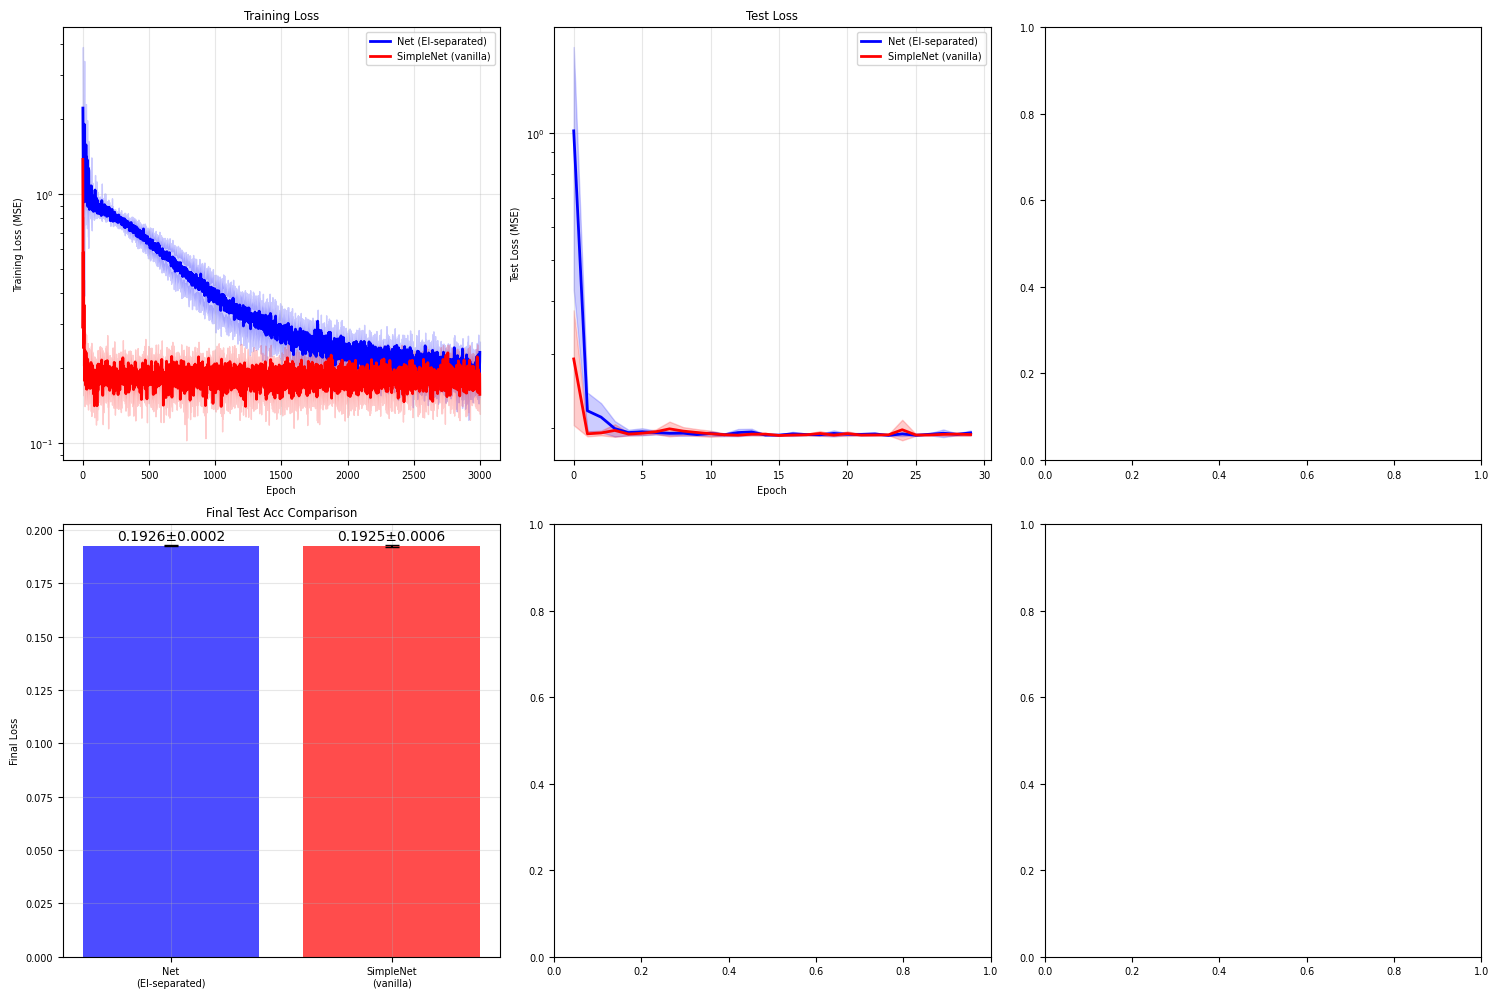

In [47]:
def plot_learning_curves(results, n_seeds):
    """
    Plot learning curves for both models.
    """
    fig, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = plt.subplots(2, 3, figsize=(15, 10))

    # Training loss curves
    net_train_losses = np.array(results['net']['train_losses'])
    simple_train_losses = np.array(results['simple']['train_losses'])

    net_train_mean = np.mean(net_train_losses, axis=0)
    net_train_std = np.std(net_train_losses, axis=0)
    simple_train_mean = np.mean(simple_train_losses, axis=0)
    simple_train_std = np.std(simple_train_losses, axis=0)
    print('net train mean:', net_train_mean)
    print(np.where(net_train_losses>100))

    epochs_range = range(len(net_train_mean))

    ax1.plot(epochs_range, net_train_mean, 'b-', label='Net (EI-separated)', linewidth=2)
    ax1.fill_between(epochs_range, net_train_mean - net_train_std, net_train_mean + net_train_std, alpha=0.2, color='blue')
    ax1.plot(epochs_range, simple_train_mean, 'r-', label='SimpleNet (vanilla)', linewidth=2)
    ax1.fill_between(epochs_range, simple_train_mean - simple_train_std, simple_train_mean + simple_train_std, alpha=0.2, color='red')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Training Loss (MSE)')
    ax1.set_title('Training Loss')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    ax1.set_yscale('log')

    # Test loss curves (subset of epochs)
    if results['net']['test_losses'][0] is not None:  # Check if test losses exist
        net_test_losses = np.array(results['net']['test_losses'])
        simple_test_losses = np.array(results['simple']['test_losses'])

        net_test_mean = np.mean(net_test_losses, axis=0)
        net_test_std = np.std(net_test_losses, axis=0)
        simple_test_mean = np.mean(simple_test_losses, axis=0)
        simple_test_std = np.std(simple_test_losses, axis=0)

        test_epochs = range(0, len(net_train_mean))[:len(net_test_mean)]

        ax2.plot(test_epochs, net_test_mean, 'b-', label='Net (EI-separated)', linewidth=2)
        ax2.fill_between(test_epochs, net_test_mean - net_test_std, net_test_mean + net_test_std, alpha=0.2, color='blue')
        ax2.plot(test_epochs, simple_test_mean, 'r-', label='SimpleNet (vanilla)', linewidth=2)
        ax2.fill_between(test_epochs, simple_test_mean - simple_test_std, simple_test_mean + simple_test_std, alpha=0.2, color='red')
        ax2.set_xlabel('Epoch')
        ax2.set_ylabel('Test Loss (MSE)')
        ax2.set_title('Test Loss')
        ax2.legend()
        ax2.grid(True, alpha=0.3)
        ax2.set_yscale('log')


    # Final Loss comparison
    net_loss = results['net']['final_loss']
    simple_loss = results['simple']['final_loss']

    x_pos = [0, 1]
    loss_means = [np.mean(net_loss), np.mean(simple_loss)]
    loss_stds = [np.std(net_loss)/np.sqrt(len(net_loss)), np.std(simple_loss)/np.sqrt(len(simple_loss))]

    bars = ax4.bar(x_pos, loss_means, yerr=loss_stds, capsize=5,
                   color=['blue', 'red'], alpha=0.7,
                   label=['Net (EI-separated)', 'SimpleNet (vanilla)'])
    ax4.set_ylabel('Final Loss')
    ax4.set_title('Final Test Acc Comparison')
    ax4.set_xticks(x_pos)
    ax4.set_xticklabels(['Net\n(EI-separated)', 'SimpleNet\n(vanilla)'])
    ax4.grid(True, alpha=0.3)

    # Add value labels on bars
    for i, (bar, mean, std) in enumerate(zip(bars, loss_means, loss_stds)):
        ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + std + 0.001,
                f'{mean:.4f}±{std:.4f}', ha='center', va='bottom', fontsize=10)


    plt.tight_layout()
    plt.show()

# Plot the results
plot_learning_curves(results, n_seeds)

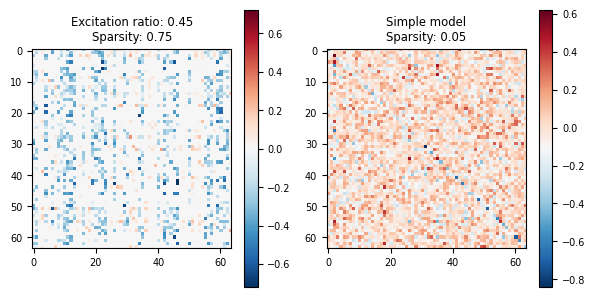

In [48]:
weight = net.get_actual_weight().detach().cpu().numpy()
fig, ax = plt.subplots(1,2,figsize=(6,3))
limit = 0.9*max(np.max(weight), np.max(-weight))
im = ax[0].imshow(weight, cmap='RdBu_r', vmin=-limit, vmax=limit)
sparsity = 1 - np.mean(np.abs(weight)>0.1*np.std(np.abs(weight)))
eimask = net.lstm.eimask_logit.detach().cpu().numpy()
# mask = F.gumbel_softmax(net.lstm.eimask_logit, tau=0.1, hard=False, dim=-1).detach().cpu().numpy()
exc_ratio = np.mean(eimask[:, 0] > eimask[:, 1])
ax[0].set_title(f'Excitation ratio: {exc_ratio:.2f}\nSparsity: {sparsity:.2f}')
plt.colorbar(im, ax=ax[0])

weight_simple = simple_net.get_actual_weight().detach().cpu().numpy()
im = ax[1].imshow(weight_simple, cmap='RdBu_r')
sparsity_simple = 1 - np.mean(np.abs(weight_simple)>0.1*np.std(np.abs(weight_simple)))
ax[1].set_title(f'Simple model\nSparsity: {sparsity_simple:.2f}')
plt.colorbar(im, ax=ax[1])
plt.tight_layout()
